# Differential Privacy: Interactive OpenDP Lab

**TU Berlin | Privacy-Preserving Computing | Chapter 2**

**Learning goals:** Understand neighbouring datasets and sensitivity; observe how ε changes the Laplace mechanism; distinguish *density* from *point probability*; inspect privacy–accuracy trade-offs; apply sequential, advanced, and parallel composition; and perform privacy-accounted releases using **OpenDP**.

**How to use this lab:** Run the cells from top to bottom. At every **Try it** prompt, change the named parameter and run that cell again. Sections 1–6 use **synthetic data and NumPy simulations** for intuition. Section 7 uses **OpenDP's actual privacy accountant**. The simulations themselves are not a suitable substitute for a vetted DP library.

**Conceptual connection to the slides:** The four incomes and the three privacy costs are the same as in the lecture's count-query example. All text and examples are in English so the notebook can be handed directly to students.

## 1. Neighbouring datasets and global sensitivity

**Basic intuition:** A single person should not be able to change a count by more than one. We use **add/remove-one adjacency**, meaning neighbouring datasets differ in the presence of one person's row.

Our count query is: **"How many people earn more than 60K?"** The synthetic income values are Alice 60K, Bob 45K, Carol 70K, and Dave 80K. Removing Dave changes the count from 2 to 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

people = ["Alice", "Bob", "Carol", "Dave"]
incomes_k = np.array([60, 45, 70, 80])
THRESHOLD_K = 60  # Try it: choose 45, 60, or 75.

def count_above(incomes, threshold=THRESHOLD_K):
    return int(np.count_nonzero(incomes > threshold))

exact_count = count_above(incomes_k)
without_dave = count_above(incomes_k[:-1])
print(f"Count on D: {exact_count}")
print(f"Count on D' (without Dave): {without_dave}")
print(f"Absolute change: {abs(exact_count - without_dave)}")

Count on D: 2
Count on D' (without Dave): 1
Absolute change: 1


Removing different people does not always change the result. The chart below shows what happens when **one person** is removed at a time. For this count query, the **global sensitivity** is 1 because any single addition or removal can change the count by *at most* one, regardless of the dataset.

\[
\Delta f=\max_{D\sim D'} |f(D)-f(D')|=1.
\]

Here, \(f\) is the count query, \(D\sim D'\) means neighbouring datasets, and \(\Delta f\) is its global sensitivity. The chart illustrates the bound for our four examples; the single-contribution argument establishes it generally.

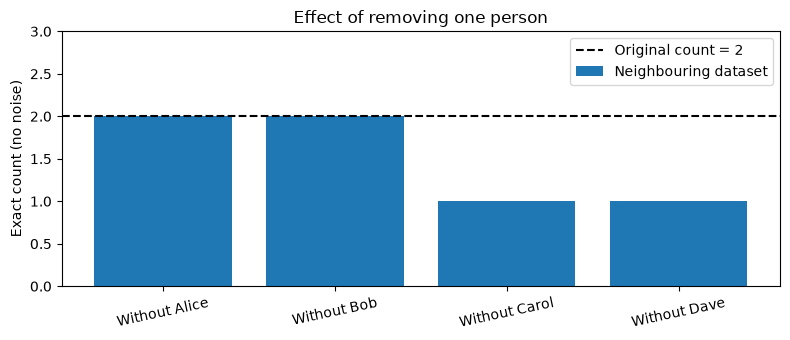

In [2]:
removed_counts = [count_above(np.delete(incomes_k, i)) for i in range(len(people))]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([f"Without {name}" for name in people], removed_counts, label="Neighbouring dataset")
ax.axhline(exact_count, ls="--", color="black", label=f"Original count = {exact_count}")
ax.set(ylabel="Exact count (no noise)", title="Effect of removing one person")
ax.set_ylim(0, max(3, exact_count + 1))
ax.legend()
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

## 2. Laplace mechanism: What ε changes

**Basic intuition:** We add random noise to the exact count so that a single person's presence is harder to infer. Smaller **ε** means a **larger noise scale** and a wider distribution of possible answers.

\[
M(D)=f(D)+\eta,\qquad \eta\sim\mathrm{Laplace}(0,b),\qquad b=\frac{\Delta f}{\varepsilon}.
\]

Here, \(M(D)\) is the released result, \(f(D)\) is the exact count, \(\eta\) is Laplace noise, \(b\) is its scale, \(\Delta f=1\) is the sensitivity, and \(\varepsilon>0\) is the per-query privacy parameter.

**Try it:** Change `EPSILON_VALUES`. The curves are simulated **probability densities**, not probabilities of individual exact outputs.

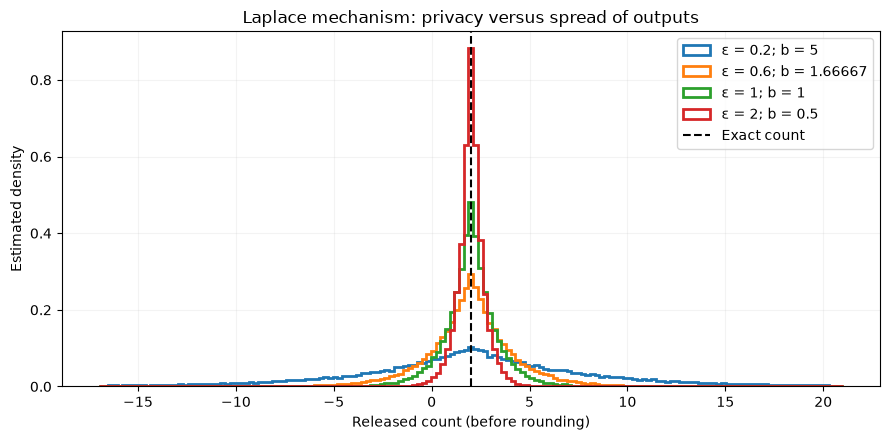

In [3]:
EPSILON_VALUES = [0.2, 0.6, 1.0, 2.0]
N_SIMULATIONS = 50_000
rng_plot = np.random.default_rng(21)

fig, ax = plt.subplots(figsize=(9, 4.5))
for eps in EPSILON_VALUES:
    if eps <= 0:
        raise ValueError("ε must be positive")
    outputs = exact_count + rng_plot.laplace(0.0, 1.0 / eps, N_SIMULATIONS)
    ax.hist(outputs, bins=np.linspace(-17, 21, 160), density=True,
            histtype="step", lw=2, label=f"ε = {eps:g}; b = {1/eps:g}")
ax.axvline(exact_count, color="black", ls="--", lw=1.5, label="Exact count")
ax.set(xlabel="Released count (before rounding)", ylabel="Estimated density",
       title="Laplace mechanism: privacy versus spread of outputs")
ax.legend()
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

## 3. From a density to an actual probability

**Basic intuition:** Unrounded Laplace noise produces a continuous value, so the probability of **one exact number** is zero. If we **round the result to the nearest integer**, we can compare meaningful point probabilities. Rounding is *post-processing* and does not weaken the DP guarantee.

We compare two neighbouring datasets: \(f(D)=2\) and \(f(D')=1\), where \(D'\) is missing Dave. We inspect the single possible **released value 2**.

\[
\Pr[M(D)=2]\leq e^{\varepsilon}\Pr[M(D')=2].
\]

Here, \(M\) is the *rounded* Laplace mechanism, \(D,D'\) are neighbouring datasets, and \(\varepsilon\) controls the allowed multiplicative difference. **Important:** Verifying one output event does **not** prove DP for every event and every neighbouring pair. The guarantee comes from the calibrated Laplace mechanism plus post-processing.

**Try it:** Set `EPSILON_CHECK` to `0.2` or `0.6`. For the second lecture query, additionally change `COUNT_D=3`, `COUNT_DPRIME=2`, and `OUTPUT_TO_CHECK=3`.

P(M(D)=2)                  = 9.52% (simulation 9.48%)
P(M(D')=2)                 = 8.20% (simulation 8.20%)
exp(ε) · P(M(D')=2)         = 10.02%
DP inequality for this one event: satisfied


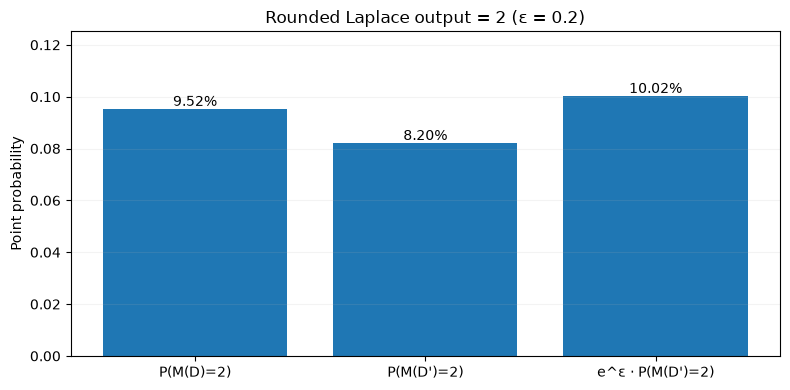

In [4]:
EPSILON_CHECK = 0.2
COUNT_D = 2
COUNT_DPRIME = 1
OUTPUT_TO_CHECK = 2
N_ROUNDED_SAMPLES = 200_000
if EPSILON_CHECK <= 0:
    raise ValueError("ε must be positive")

b_check = 1.0 / EPSILON_CHECK
rng_check = np.random.default_rng(2026)
outputs_D = np.rint(COUNT_D + rng_check.laplace(0, b_check, N_ROUNDED_SAMPLES))
outputs_Dprime = np.rint(COUNT_DPRIME + rng_check.laplace(0, b_check, N_ROUNDED_SAMPLES))
p_sim = np.mean(outputs_D == OUTPUT_TO_CHECK)
q_sim = np.mean(outputs_Dprime == OUTPUT_TO_CHECK)

# Exact mass after rounding: P(round(X) = k) = F(k+0.5) - F(k-0.5).
def laplace_cdf(x, mu, b):
    return (0.5 * np.exp((x - mu) / b) if x < mu
            else 1 - 0.5 * np.exp(-(x - mu) / b))

def rounded_probability(k, mu, b):
    return laplace_cdf(k + 0.5, mu, b) - laplace_cdf(k - 0.5, mu, b)

p_exact = rounded_probability(OUTPUT_TO_CHECK, COUNT_D, b_check)
q_exact = rounded_probability(OUTPUT_TO_CHECK, COUNT_DPRIME, b_check)
bound_exact = np.exp(EPSILON_CHECK) * q_exact
print(f"P(M(D)={OUTPUT_TO_CHECK})                  = {p_exact:.2%} (simulation {p_sim:.2%})")
print(f"P(M(D')={OUTPUT_TO_CHECK})                 = {q_exact:.2%} (simulation {q_sim:.2%})")
print(f"exp(ε) · P(M(D')={OUTPUT_TO_CHECK})         = {bound_exact:.2%}")
print("DP inequality for this one event:", "satisfied" if p_exact <= bound_exact+1e-12 else "violated")

fig, ax = plt.subplots(figsize=(8, 4))
labels = [f"P(M(D)={OUTPUT_TO_CHECK})", f"P(M(D')={OUTPUT_TO_CHECK})",
          f"e^ε · P(M(D')={OUTPUT_TO_CHECK})"]
values = [p_exact, q_exact, bound_exact]
bars = ax.bar(labels, values)
for bar, value in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{value:.2%}",
            ha="center", va="bottom")
ax.set(ylabel="Point probability", title=f"Rounded Laplace output = {OUTPUT_TO_CHECK} (ε = {EPSILON_CHECK:g})")
ax.set_ylim(0, max(values)*1.25)
ax.grid(axis="y", alpha=0.15)
plt.tight_layout()
plt.show()

## 4. Privacy–accuracy trade-off

**Basic intuition:** With less noise, results tend to be closer to the exact count, but privacy protection is weaker. One useful accuracy measure is the **expected absolute noise error**.

\[
\mathbb E[|M(D)-f(D)|]=b=\frac{1}{\varepsilon}.
\]

Here, \(\mathbb E\) denotes the expectation over repeated Laplace draws, \(M(D)\) is the *unrounded* noisy count, \(f(D)\) is the exact count, and \(b\) is the Laplace scale for sensitivity 1.

**Try it:** Change `EPSILON_GRID`, or compare the theoretical line to simulated average errors. The line describes an average over many runs, **not** a guaranteed error bound for one release.

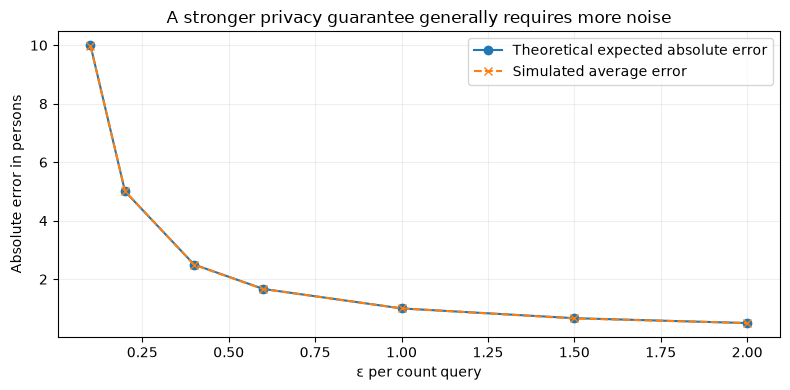

In [5]:
EPSILON_GRID = np.array([0.1, 0.2, 0.4, 0.6, 1.0, 1.5, 2.0])
if np.any(EPSILON_GRID <= 0):
    raise ValueError("All epsilon values must be positive")
rng_accuracy = np.random.default_rng(34)
mean_abs_errors = [np.abs(rng_accuracy.laplace(0, 1/eps, 40_000)).mean()
                   for eps in EPSILON_GRID]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(EPSILON_GRID, 1/EPSILON_GRID, "o-", label="Theoretical expected absolute error")
ax.plot(EPSILON_GRID, mean_abs_errors, "x--", label="Simulated average error")
ax.set(xlabel="ε per count query", ylabel="Absolute error in persons",
       title="A stronger privacy guarantee generally requires more noise")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Basic and parallel composition

**Basic intuition:** If one person can be included in multiple queries, we add their privacy costs. If each person belongs to **exactly one** of several disjoint groups, parallel composition uses the **largest** group-level privacy cost instead.

For the three sequential count queries from the lecture:

\[
\varepsilon_{\mathrm{seq}}=0.2+0.6+0.2=1.0.
\]

For independently analysed *disjoint* male and female groups:

\[
\varepsilon_{\mathrm{parallel}}=\max(0.3,0.5)=0.5.
\]

Here, each number is the privacy parameter of one mechanism. These are **pure-DP** examples, so \(\delta=0\). The parallel rule requires that every protected individual contributes to at most one of the groups. These expressions quantify the **composed guarantee**, not a random quantity spent by a particular run.

**Try it:** Change one allocation in either list. Can you identify why using `sum` on the group budgets would be unnecessarily pessimistic?

Sequential composition: ε_total = 1.00
Parallel composition:   ε_total = 0.50
Unallocated from lecture budget ε=1.0: 0.00


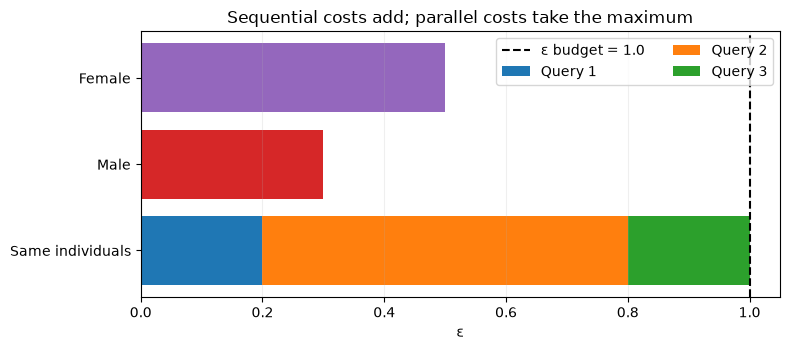

In [6]:
SEQUENTIAL_EPS = [0.2, 0.6, 0.2]
GROUP_EPS = {"Male": 0.3, "Female": 0.5}
TOTAL_ALLOWED_EPS = 1.0

if any(eps < 0 for eps in SEQUENTIAL_EPS + list(GROUP_EPS.values())):
    raise ValueError("Privacy parameters must be non-negative")
seq_total = sum(SEQUENTIAL_EPS)
parallel_total = max(GROUP_EPS.values())
print(f"Sequential composition: ε_total = {seq_total:.2f}")
print(f"Parallel composition:   ε_total = {parallel_total:.2f}")
print(f"Unallocated from lecture budget ε=1.0: {TOTAL_ALLOWED_EPS-seq_total:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
left = 0
for idx, eps in enumerate(SEQUENTIAL_EPS):
    ax.barh("Same individuals", eps, left=left, label=f"Query {idx+1}")
    left += eps
for group, eps in GROUP_EPS.items():
    ax.barh(group, eps)
ax.axvline(TOTAL_ALLOWED_EPS, ls="--", c="black", label="ε budget = 1.0")
ax.set(xlabel="ε", title="Sequential costs add; parallel costs take the maximum")
ax.legend(loc="upper right", ncol=2)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Advanced composition: when can it help? (Optional)

**Basic intuition:** For a **large number of queries with small equal ε**, Advanced Composition can yield a better *ε bound* than adding the costs directly. This comparison changes the type of guarantee: Basic Composition of pure-DP mechanisms stays **pure DP**, whereas the bound below uses an additional \(\delta'>0\).

For \(k\) mechanisms that each satisfy pure \(\varepsilon\)-DP, a classical bound is:

\[
\varepsilon_{\mathrm{adv}}=\varepsilon\sqrt{2k\ln(1/\delta')}+k\varepsilon(e^{\varepsilon}-1).
\]

Here, \(k\) is the query count, \(\varepsilon\) is the **same per-query** budget, and \(\delta'\) is the additional failure-probability parameter. Advanced Composition then guarantees \((\varepsilon_{\mathrm{adv}},\delta')\)-DP. The expression is an **upper bound**, not an exact privacy loss; for a small number of queries it can be worse than Basic Composition.

**Try it:** Vary `EPSILON_EACH` and `DELTA_PRIME`. Look for when the Advanced line falls below the Basic line. **This plot does not describe the accounting used by the OpenDP `Context` below**, which uses basic sequential composition.

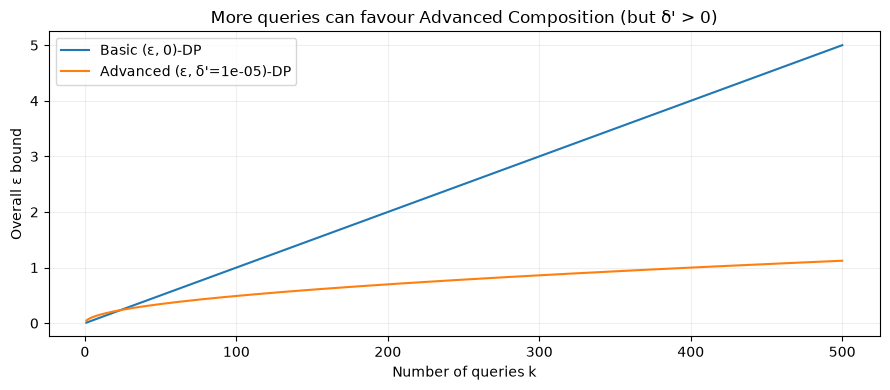

Advanced ε bound first becomes smaller at k = 24.
Note: Basic has δ=0; Advanced allows the additional δ'.


In [7]:
EPSILON_EACH = 0.01
DELTA_PRIME = 1e-5
K_MAX = 500
if EPSILON_EACH <= 0 or not 0 < DELTA_PRIME < 1:
    raise ValueError("Require ε > 0 and 0 < δ' < 1")

k = np.arange(1, K_MAX + 1)
basic_bound = k * EPSILON_EACH
advanced_bound = (EPSILON_EACH * np.sqrt(2 * k * np.log(1/DELTA_PRIME))
                  + k * EPSILON_EACH * np.expm1(EPSILON_EACH))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k, basic_bound, label="Basic (ε, 0)-DP")
ax.plot(k, advanced_bound, label=f"Advanced (ε, δ'={DELTA_PRIME:g})-DP")
ax.set(xlabel="Number of queries k", ylabel="Overall ε bound",
       title="More queries can favour Advanced Composition (but δ' > 0)")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

improves = np.flatnonzero(advanced_bound < basic_bound)
if len(improves):
    print(f"Advanced ε bound first becomes smaller at k = {k[improves[0]]}.")
else:
    print("No improvement within the displayed range.")
print("Note: Basic has δ=0; Advanced allows the additional δ'.")

## 7. The original OpenDP workflow

The remaining section follows the sequence of the **[OpenDP Typical Workflow](https://docs.opendp.org/en/stable/getting-started/typical-workflow.html)**, as in the uploaded example:

**Privacy unit → privacy loss → public bounds → data and context → DP count → accuracy interval → budget → DP mean.**

**Important difference from NumPy:** OpenDP constructs measurements with formal privacy guarantees and mediates their releases. **Re-running a `.release()` cell consumes another query allocation** in the same live context. A newly created context on the *same real private dataset* does **not** reset the actual privacy cost; a production system must track privacy spending across all contexts and releases.

The sample data here is synthetic. We may inspect exact values **only because this is a classroom demonstration**. Do not inspect raw values from a genuinely protected dataset for debugging or plotting.

### 7.1 Install and import OpenDP

Google Colab needs an internet connection to install OpenDP. The version range is intentionally bounded to the API family used in this notebook. If you already installed the package in the active runtime, pip may report that it is satisfied.

In [8]:
%pip -q install "opendp>=0.15.1,<0.17"

Note: you may need to restart the kernel to use updated packages.


In [9]:
from importlib.metadata import version
import opendp.prelude as dp

dp.enable_features("contrib")
print("OpenDP version:", version("opendp"))

OpenDP version: 0.16.0


### 7.2 Privacy unit and privacy loss

**Basic intuition:** We first tell OpenDP **what must be protected** and **how strong the guarantee must be**. With `contributions=1`, neighbouring datasets differ by one row corresponding to one person; more contributions per person require a different privacy model.

`dp.loss_of(epsilon=1.0)` specifies **pure ε-DP**: here, \(\delta=0\). The privacy parameter is selected by the curator, **not estimated from the records**. For clarity, we divide the budget into **three equal allocations**: one for the count, one for the mean, and one for a final demonstration query.

In [10]:
privacy_unit = dp.unit_of(contributions=1)
privacy_loss = dp.loss_of(epsilon=1.0)
NUMBER_OF_SLOTS = 3
print("Privacy unit:", privacy_unit)
print("Privacy loss:", privacy_loss)
print(f"Budget per release slot: ε = {1.0 / NUMBER_OF_SLOTS:.3f}")

Privacy unit: (SymmetricDistance(), 1)
Privacy loss: (MaxDivergence, 1.0)
Budget per release slot: ε = 0.333


### 7.3 Public bounds, imputations, and synthetic data

**Basic intuition:** An unbounded numerical value could change a sum or mean by arbitrarily much. **Clipping** to a known interval and **imputing** invalid/missing entries helps keep the sensitivity bounded. Bounds should come from **public domain knowledge or a privacy-protected procedure**, rather than being discovered from raw private values without accounting.

We keep the original example's range \([0,100]\) and imputation value 50. Our list contains **100 synthetic floating-point values**.

In [11]:
bounds = (0.0, 100.0)
imputed_value = 50.0
rng_data = np.random.default_rng(77)
data = rng_data.integers(0, 101, size=100).astype(float).tolist()
print("Synthetic entries:", len(data))
print("First five synthetic values (do NOT print this for real private data):", data[:5])

Synthetic entries: 100
First five synthetic values (do NOT print this for real private data): [6.0, 79.0, 64.0, 55.0, 80.0]


### 7.4 Create a single context

**Basic intuition:** A `Context` acts as the gatekeeper between the protected dataset and the outside world. It ensures that query releases stay within the **pre-allocated budget**. Here, the total ε is 1.0 and each of three slots receives ε = 1/3.

**Do not re-run this cell as a way to get more budget on real data.** The notebook creates a new synthetic context only to let students restart an experiment.

In [12]:
context = dp.Context.compositor(
    data=data,
    privacy_unit=privacy_unit,
    privacy_loss=privacy_loss,
    split_evenly_over=NUMBER_OF_SLOTS,
)
print("Available query slots:", len(context.d_mids))
print("Remaining ε allocation:", sum(context.d_mids))

Available query slots: 3
Remaining ε allocation: 1.0


### 7.5 Differentially private count

**Basic intuition:** First construct the DP measurement, then inspect its automatically calibrated scale, and **only then call `.release()`**. The latter is the actual privacy-consuming action.

OpenDP's `count().laplace()` uses an **integer-valued noise mechanism** for the count. This is *not* identical to the NumPy experiment where we sampled **continuous Laplace noise and rounded afterward**. Both have integer outputs, but their exact probability distributions and accuracy formulas differ.

In [13]:
count_query = context.query().count().laplace()
count_scale = count_query.param()
count_accuracy_95 = dp.discrete_laplacian_scale_to_accuracy(
    scale=count_scale, alpha=0.05
)
print("Count noise scale:", count_scale)
print("95% noise-error radius:", count_accuracy_95)

Count noise scale: 3.0000000000000004
95% noise-error radius: 9.445721638273584


`alpha=0.05` asks for a **95% noise-error radius**: over repeated runs on a fixed dataset, the difference between the noisy and exact count is within this radius with at least 95% probability. This is **not** a statistical confidence interval for a population parameter.

**Next cell spends the first query allocation.** Running it again produces another DP release and consumes further privacy budget.

In [14]:
dp_count = count_query.release()
count_noise_interval = (dp_count - count_accuracy_95,
                        dp_count + count_accuracy_95)
print("Released DP count:", dp_count)
print("95% noise interval for the original count:", count_noise_interval)
print("Exact count (shown ONLY because data are synthetic):", len(data))

Released DP count: 99
95% noise interval for the original count: (89.55427836172642, 108.44572163827358)
Exact count (shown ONLY because data are synthetic): 100


### 7.6 Visualise one real OpenDP release

This interval comes from a **noise distribution**, not from sampling uncertainty. One observed release may fall outside its nominal 95% interval; this is possible in 5% of repeated runs. The exact count is shown as a reference **only because the dataset is synthetic**.

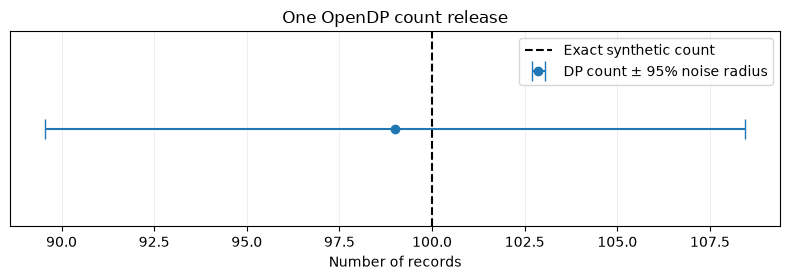

In [15]:
fig, ax = plt.subplots(figsize=(8, 2.9))
ax.errorbar([dp_count], [1], xerr=[count_accuracy_95], fmt="o",
            capsize=7, label="DP count ± 95% noise radius")
ax.axvline(len(data), ls="--", c="black", label="Exact synthetic count")
ax.set(xlabel="Number of records", title="One OpenDP count release")
ax.set_yticks([])
ax.set_ylim(0.65, 1.35)
ax.grid(axis="x", alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

### 7.7 Check the remaining privacy budget

`context.d_mids` holds the **remaining planned allocations**. In this example, it starts with three slots; after the first release, two remain. In contrast, `context.d_mids_consumed` records allocations that have already been used.

**Try it:** Run this cell again after the mean release below. Notice that the remaining budget changes even though the original privacy limit does not.

In [16]:
print("Consumed allocations:", context.d_mids_consumed)
print("Remaining allocations:", context.d_mids)
print(f"Total consumed ε: {sum(context.d_mids_consumed):.3f}")
print(f"Total remaining ε: {sum(context.d_mids):.3f}")

Consumed allocations: [0.3333333333333333]
Remaining allocations: [0.3333333333333333, 0.3333333333333333]
Total consumed ε: 0.333
Total remaining ε: 0.667


### 7.8 Differentially private mean

**Basic intuition:** A mean needs **bounded values** and a controlled **denominator**. The original OpenDP workflow imputes missing values, clamps to public bounds, **resizes using the already released DP count**, then adds Laplace noise to the mean.

The released count is already DP. Using it as a parameter is **post-processing of that release**; the separate mean release still consumes its own budget allocation. To avoid an invalid resize in the extremely unlikely event of a nonpositive noisy count, we clip the size to at least 1.

For **continuous Laplace noise**, a 95% noise-error radius is:

\[
 r_{0.95}=-b\ln(0.05).
\]

Here, \(b\) is the scale returned by `mean_query.param()` and \(r_{0.95}\) describes the noise added to the **preprocessed mean**. It does **not** include distortions caused by clamping, imputation, or resizing, and it is **not** a population confidence interval.

In [17]:
size_for_mean = max(1, int(dp_count))  # post-processing of the DP count
mean_query = (
    context.query()
    .impute_constant(imputed_value)
    .clamp(bounds)
    .resize(size=size_for_mean, constant=imputed_value)
    .mean()
    .laplace()
)
mean_scale = mean_query.param()
mean_noise_radius_95 = -mean_scale * np.log(0.05)
print("DP resize target:", size_for_mean)
print("Mean noise scale:", mean_scale)
print("95% noise-error radius:", mean_noise_radius_95)

DP resize target: 99
Mean noise scale: 3.0303030303039566
95% noise-error radius: 9.07797658653002


In [18]:
dp_mean = mean_query.release()  # second budget-consuming release
print("Released DP mean:", dp_mean)
print("95% interval around preprocessed mean:",
      (dp_mean - mean_noise_radius_95, dp_mean + mean_noise_radius_95))
print(f"Remaining ε: {sum(context.d_mids):.3f}")

Released DP mean: 49.48330141491308
95% interval around preprocessed mean: (np.float64(40.40532482838306), np.float64(58.5612780014431))
Remaining ε: 0.333


### 7.9 Privacy accountant: use the last slot, then stop

**Basic intuition:** OpenDP prevents additional releases once there are no allocations left. We use a **third count** to consume the final slot and then attempt a fourth query. The exception is expected and demonstrates that the context has enforced its allocation limit.

**Only run the following cell once after the count and mean cells.** If you rerun an earlier release, you may have already used the last slot. To start over on the synthetic dataset, restart the runtime and run the notebook from the top.

In [19]:
print("Slots before third release:", len(context.d_mids))
last_count = context.query().count().laplace().release()
print("Final DP count:", last_count)
print("Slots after third release:", len(context.d_mids))

try:
    extra_result = context.query().count().laplace().release()
    print("Unexpected fourth release:", extra_result)
except Exception as exc:
    print("Fourth release blocked as expected:", type(exc).__name__)
print("Total consumed ε:", sum(context.d_mids_consumed))

Slots before third release: 1
Final DP count: 100
Slots after third release: 0
Fourth release blocked as expected: ValueError
Total consumed ε: 1.0


## 8. Exercises and discussion

1. Change `THRESHOLD_K` in Section 1. Which removals change the count, and why does the *global* sensitivity remain 1?
2. Set `EPSILON_CHECK = 0.6`, `COUNT_D = 3`, `COUNT_DPRIME = 2`, and `OUTPUT_TO_CHECK = 3` in Section 3. Compare the probabilities with the lecture's second query.
3. In Section 4, halve ε. How do the distribution and the average absolute error change? Is one individual release guaranteed to be accurate?
4. In Section 5, suppose one person appears in both groups. Would the maximum rule still apply? Explain the privacy-unit requirement.
5. In Section 6, why can Advanced Composition provide a smaller ε bound for many queries but still give a different **type** of DP guarantee?
6. In Section 7, explain why re-running a `.release()` cell may consume another allocation, and why opening a new context does not truly reset privacy spending on the same private data.

**Instructor note:** Answers should explicitly distinguish illustrative simulation from formal privacy accounting, and the probability distribution of a discrete OpenDP count from a rounded continuous Laplace count.

### References

The live **OpenDP Context API** portion is adapted from the uploaded notebook and the [OpenDP Typical Workflow](https://docs.opendp.org/en/stable/getting-started/typical-workflow.html). Additional references: [OpenDP Context API](https://docs.opendp.org/en/stable/api/python/opendp.context.html), [Additive Noise Mechanisms](https://docs.opendp.org/en/stable/api/user-guide/measurements/additive-noise-mechanisms.html), and Dwork & Roth, *The Algorithmic Foundations of Differential Privacy* (composition and Laplace mechanism).